In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [3]:
import os

print("Current working folder:")
print(os.getcwd())

Current working folder:
C:\Users\RAGA AMIRTHA


In [6]:
import os

dataset_path = r"C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data"

print("Dataset path:")
print(dataset_path)

print("\nContents:")
print(os.listdir(dataset_path))

Dataset path:
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data

Contents:
['casting_data']


In [7]:
dataset_path = r"C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data"

print("Dataset path:")
print(dataset_path)

print("\nContents:")
print(os.listdir(dataset_path))

Dataset path:
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data

Contents:
['test', 'train']


In [8]:
train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

train_defective = os.path.join(train_path, "def_front")
train_ok = os.path.join(train_path, "ok_front")

test_defective = os.path.join(test_path, "def_front")
test_ok = os.path.join(test_path, "ok_front")

print("TRAIN DATA")
print("Defective images:", len(os.listdir(train_defective)))
print("OK images:", len(os.listdir(train_ok)))

print("\nTEST DATA")
print("Defective images:", len(os.listdir(test_defective)))
print("OK images:", len(os.listdir(test_ok)))

TRAIN DATA
Defective images: 3758
OK images: 2875

TEST DATA
Defective images: 453
OK images: 262


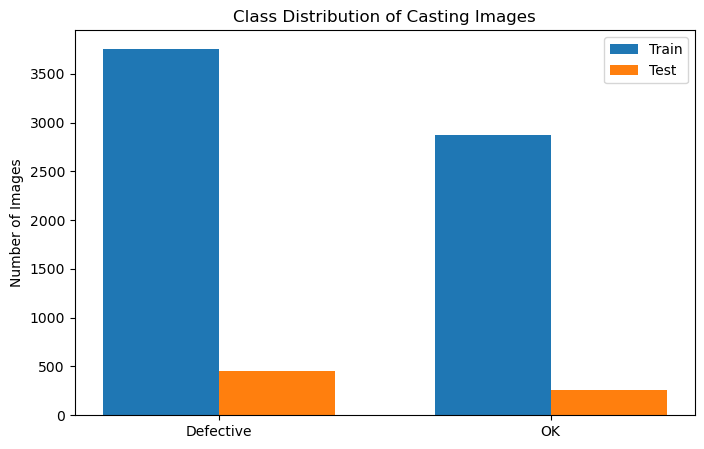

In [10]:
train_counts = [
    len(os.listdir(train_defective)),
    len(os.listdir(train_ok))
]

test_counts = [
    len(os.listdir(test_defective)),
    len(os.listdir(test_ok))
]

classes = ["Defective", "OK"]

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, train_counts, width, label="Train")
plt.bar(x + width/2, test_counts, width, label="Test")

plt.xticks(x, classes)
plt.ylabel("Number of Images")
plt.title("Class Distribution of Casting Images")
plt.legend()

plt.show()

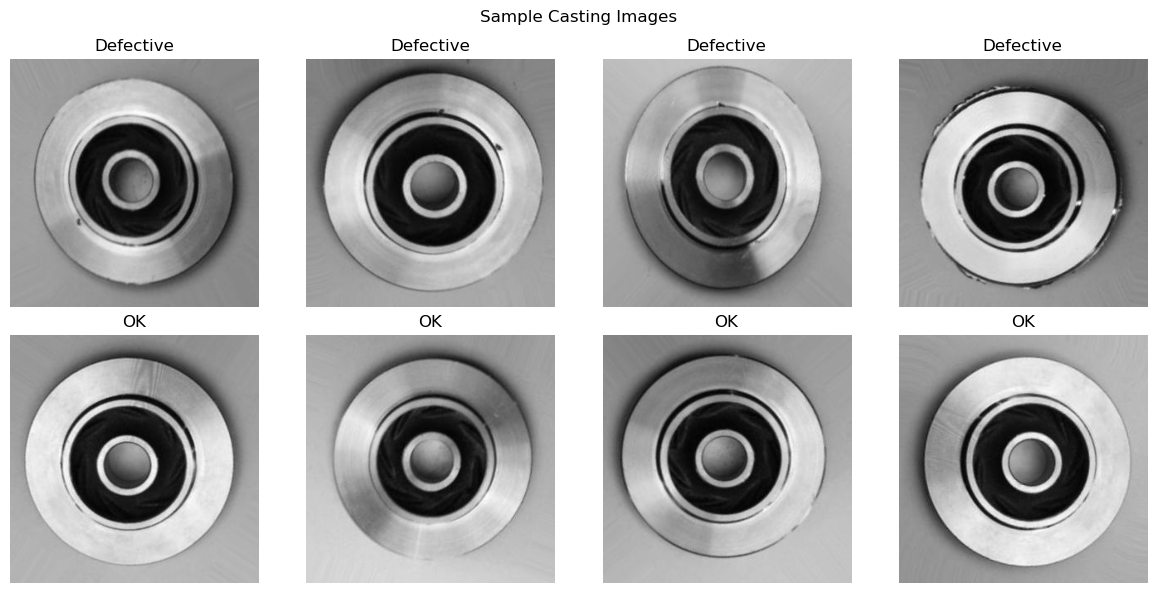

In [11]:
from PIL import Image

defective_files = [
    os.path.join(train_defective, f)
    for f in os.listdir(train_defective)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

ok_files = [
    os.path.join(train_ok, f)
    for f in os.listdir(train_ok)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

plt.figure(figsize=(12, 6))

for i in range(4):
    img = Image.open(defective_files[i])
    
    plt.subplot(2, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("Defective")
    plt.axis("off")

for i in range(4):
    img = Image.open(ok_files[i])
    
    plt.subplot(2, 4, i + 5)
    plt.imshow(img, cmap="gray")
    plt.title("OK")
    plt.axis("off")

plt.suptitle("Sample Casting Images")
plt.tight_layout()
plt.show()

In [12]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []
labels = []

# Defective = 1
for filename in os.listdir(train_defective):
    if filename.lower().endswith(image_extensions):
        image_paths.append(os.path.join(train_defective, filename))
        labels.append(1)

# OK = 0
for filename in os.listdir(train_ok):
    if filename.lower().endswith(image_extensions):
        image_paths.append(os.path.join(train_ok, filename))
        labels.append(0)

train_df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("Total training images:", len(train_df))
print("\nLabel counts:")
print(train_df["label"].value_counts())

print("\nFirst 5 rows:")
print(train_df.head())

Total training images: 6633

Label counts:
label
1    3758
0    2875
Name: count, dtype: int64

First 5 rows:
                                            filepath  label
0  C:\Users\RAGA AMIRTHA\Downloads\casting_data\c...      1
1  C:\Users\RAGA AMIRTHA\Downloads\casting_data\c...      1
2  C:\Users\RAGA AMIRTHA\Downloads\casting_data\c...      1
3  C:\Users\RAGA AMIRTHA\Downloads\casting_data\c...      1
4  C:\Users\RAGA AMIRTHA\Downloads\casting_data\c...      1


In [13]:
train_df, val_df = train_test_split(
    train_df,
    test_size=0.15,
    stratify=train_df["label"],
    random_state=SEED
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

Training images: 5638
Validation images: 995

Training class distribution:
label
1    3194
0    2444
Name: count, dtype: int64

Validation class distribution:
label
1    564
0    431
Name: count, dtype: int64


In [14]:
from PIL import Image

sample_path = train_df.iloc[0]["filepath"]

sample_image = Image.open(sample_path)

print("Image path:")
print(sample_path)

print("\nImage size:", sample_image.size)
print("Image mode:", sample_image.mode)

Image path:
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data\train\ok_front\cast_ok_0_740.jpeg

Image size: (300, 300)
Image mode: RGB


In [15]:
IMG_SIZE = 160
BATCH_SIZE = 32

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 160 x 160
Batch size: 32


In [16]:
def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, tf.cast(label, tf.float32)

In [17]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["filepath"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["filepath"].values, val_df["label"].values)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_df),
    seed=SEED
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [18]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 160, 160, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 0.9991728


In [19]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers initially
base_model.trainable = False

# Build our classifier
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = layers.RandomRotation(0.05)(inputs)
x = layers.RandomZoom(0.10)(x)
x = layers.RandomContrast(0.10)(x)

x = layers.Rescaling(2.0, offset=-1.0)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_contrast (RandomContrast)     │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weight = {
    0: class_weights_array[0],
    1: class_weights_array[1]
}

print("Class weights:")
print("OK (0):", class_weight[0])
print("Defective (1):", class_weight[1])

Class weights:
OK (0): 1.1534369885433715
Defective (1): 0.882592360676268


In [21]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

print("Training callbacks are ready.")

Training callbacks are ready.


In [22]:
import time

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weight,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Training time: {training_time / 60:.2f} minutes")

Epoch 1/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 29s 128ms/step - accuracy: 0.8072 - loss: 0.4268 - precision: 0.8469 - recall: 0.8053 - val_accuracy: 0.8804 - val_loss: 0.2794 - val_precision: 1.0000 - val_recall: 0.7890 - learning_rate: 0.0010
Epoch 2/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 22s 116ms/step - accuracy: 0.9257 - loss: 0.2262 - precision: 0.9530 - recall: 0.9139 - val_accuracy: 0.9558 - val_loss: 0.1520 - val_precision: 1.0000 - val_recall: 0.9220 - learning_rate: 0.0010
Epoch 3/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 22s 118ms/step - accuracy: 0.9409 - loss: 0.1755 - precision: 0.9604 - recall: 0.9343 - val_accuracy: 0.9628 - val_loss: 0.1248 - val_precision: 1.0000 - val_recall: 0.9344 - learning_rate: 0.0010
Epoch 4/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 22s 119ms/step - accuracy: 0.9518 - loss: 0.1456 - precision: 0.9713 - recall: 0.9427 - val_accuracy: 0.9719 - val_loss: 0.0957 - val_precision: 1.0000 - val_recall: 0.9504 - learning_rate: 0.0010
Epoch 5/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 24s 123ms/step - 

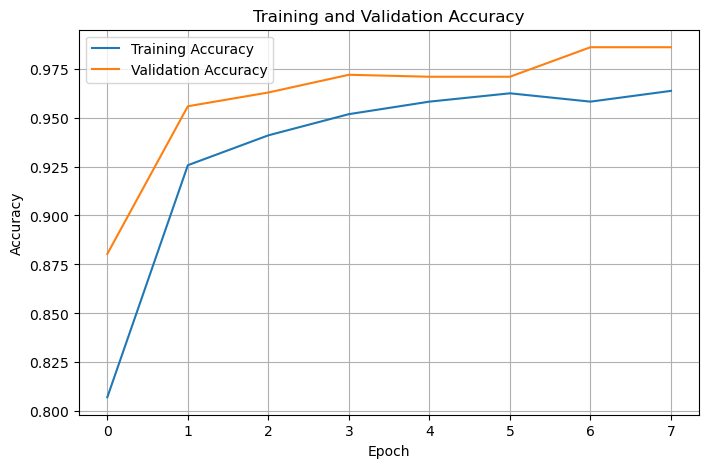

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

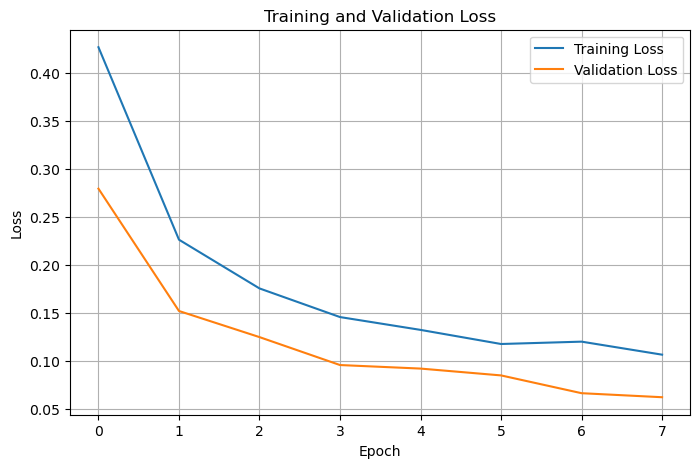

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [25]:
val_probs = model.predict(val_ds).ravel()

val_true = val_df["label"].values

print("Validation predictions:", len(val_probs))
print("Validation true labels:", len(val_true))

print("\nFirst 10 predicted probabilities:")
print(val_probs[:10])

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 140ms/step
Validation predictions: 995
Validation true labels: 995

First 10 predicted probabilities:
[0.0092174  0.9931266  0.3909524  0.01689729 0.02251218 0.9776474
 0.08036505 0.976811   0.99994016 0.0148626 ]


In [26]:
thresholds = np.arange(0.10, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:
    val_pred = (val_probs >= threshold).astype(int)

    precision = precision_score(
        val_true,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        val_true,
        val_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_true,
        val_pred,
        zero_division=0
    )

    f2 = (5 * precision * recall) / (4 * precision + recall) \
        if (precision + recall) > 0 else 0

    false_negatives = np.sum(
        (val_true == 1) & (val_pred == 0)
    )

    false_positives = np.sum(
        (val_true == 0) & (val_pred == 1)
    )

    threshold_results.append([
        threshold,
        precision,
        recall,
        f1,
        f2,
        false_negatives,
        false_positives
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=[
        "Threshold",
        "Precision",
        "Defective Recall",
        "F1",
        "F2",
        "False Negatives",
        "False Positives"
    ]
)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Defective Recall     F1     F2  False Negatives  False Positives
      0.10     0.8690            1.0000 0.9299 0.9707                0               85
      0.15     0.9022            0.9982 0.9478 0.9774                1               61
      0.20     0.9259            0.9965 0.9599 0.9815                2               45
      0.25     0.9476            0.9947 0.9706 0.9849                3               31
      0.30     0.9639            0.9947 0.9791 0.9884                3               21
      0.35     0.9705            0.9911 0.9807 0.9869                5               17
      0.40     0.9773            0.9911 0.9842 0.9883                5               13
      0.45     0.9824            0.9876 0.9850 0.9865                7               10
      0.50     0.9911            0.9840 0.9875 0.9854                9                5
      0.55     1.0000            0.9787 0.9892 0.9829               12                0
      0.60     1.0000           

In [27]:
BEST_THRESHOLD = 0.30

print("Selected threshold:", BEST_THRESHOLD)
print("Reason: Prioritize high recall for detecting defective castings.")

Selected threshold: 0.3
Reason: Prioritize high recall for detecting defective castings.


In [28]:
test_image_paths = []
test_labels = []

# Defective = 1
for filename in os.listdir(test_defective):
    if filename.lower().endswith(image_extensions):
        test_image_paths.append(
            os.path.join(test_defective, filename)
        )
        test_labels.append(1)

# OK = 0
for filename in os.listdir(test_ok):
    if filename.lower().endswith(image_extensions):
        test_image_paths.append(
            os.path.join(test_ok, filename)
        )
        test_labels.append(0)

test_df = pd.DataFrame({
    "filepath": test_image_paths,
    "label": test_labels
})

print("Total test images:", len(test_df))

print("\nTest class distribution:")
print(test_df["label"].value_counts())

print("\nExpected:")
print("Defective:", len(test_defective) and len(os.listdir(test_defective)))
print("OK:", len(test_ok) and len(os.listdir(test_ok)))

Total test images: 715

Test class distribution:
label
1    453
0    262
Name: count, dtype: int64

Expected:
Defective: 453
OK: 262


In [29]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["filepath"].values, test_df["label"].values)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Test TensorFlow dataset created successfully.")

Test TensorFlow dataset created successfully.


In [30]:
test_probs = model.predict(test_ds).ravel()

test_true = test_df["label"].values

test_pred = (test_probs >= BEST_THRESHOLD).astype(int)

print("Test predictions:", len(test_probs))
print("Test true labels:", len(test_true))

print("\nThreshold used:", BEST_THRESHOLD)

print("\nFirst 10 predicted probabilities:")
print(test_probs[:10])

print("\nFirst 10 predicted labels:")
print(test_pred[:10])

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step
Test predictions: 715
Test true labels: 715

Threshold used: 0.3

First 10 predicted probabilities:
[0.95336306 0.99585736 0.99998766 0.97877735 0.99975294 0.8922537
 0.961775   0.9989089  0.9992843  0.9713199 ]

First 10 predicted labels:
[1 1 1 1 1 1 1 1 1 1]


In [31]:
# Calculate final test metrics

test_accuracy = accuracy_score(test_true, test_pred)

test_precision = precision_score(
    test_true,
    test_pred,
    zero_division=0
)

test_recall = recall_score(
    test_true,
    test_pred,
    zero_division=0
)

test_f1 = f1_score(
    test_true,
    test_pred,
    zero_division=0
)

test_macro_f1 = f1_score(
    test_true,
    test_pred,
    average="macro",
    zero_division=0
)

print("FINAL TEST RESULTS")
print("=" * 40)

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Precision:         {test_precision:.4f}")
print(f"Defective Recall:  {test_recall:.4f}")
print(f"Defective F1:      {test_f1:.4f}")
print(f"Macro F1:          {test_macro_f1:.4f}")

FINAL TEST RESULTS
Accuracy:          0.9692
Precision:         0.9556
Defective Recall:  0.9978
Defective F1:      0.9762
Macro F1:          0.9663


In [32]:
print("CLASSIFICATION REPORT")
print("=" * 60)

report = classification_report(
    test_true,
    test_pred,
    target_names=["OK", "Defective"],
    digits=4,
    zero_division=0
)

print(report)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          OK     0.9959    0.9198    0.9563       262
   Defective     0.9556    0.9978    0.9762       453

    accuracy                         0.9692       715
   macro avg     0.9757    0.9588    0.9663       715
weighted avg     0.9704    0.9692    0.9690       715



CONFUSION MATRIX
[[241  21]
 [  1 452]]


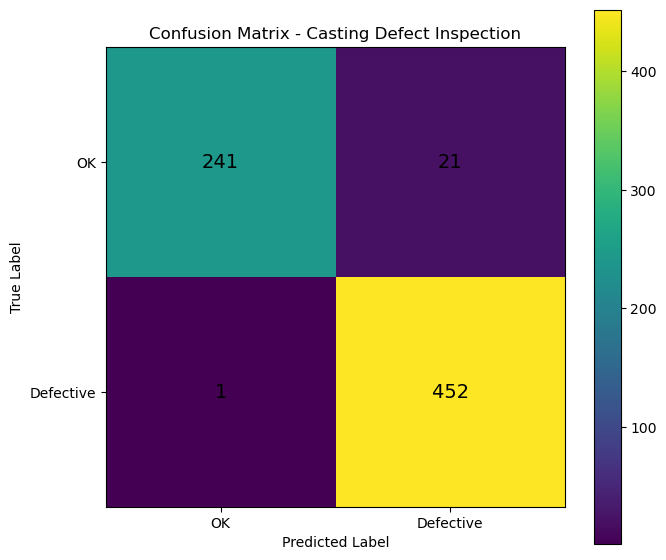

In [33]:
cm = confusion_matrix(test_true, test_pred)

print("CONFUSION MATRIX")
print("=" * 40)
print(cm)

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title("Confusion Matrix - Casting Defect Inspection")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], ["OK", "Defective"])
plt.yticks([0, 1], ["OK", "Defective"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [34]:
    # Create a results table for the test set

test_results = test_df.copy()

test_results["true_label"] = test_true
test_results["predicted_label"] = test_pred
test_results["probability_defective"] = test_probs

# Find all misclassified images
misclassified = test_results[
    test_results["true_label"] != test_results["predicted_label"]
].copy()

# Separate false negatives and false positives
false_negatives = misclassified[
    (misclassified["true_label"] == 1) &
    (misclassified["predicted_label"] == 0)
]

false_positives = misclassified[
    (misclassified["true_label"] == 0) &
    (misclassified["predicted_label"] == 1)
]

print("Total misclassified:", len(misclassified))
print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

print("\nFALSE NEGATIVE:")
print(false_negatives[
    ["filepath", "probability_defective"]
].to_string(index=False))

Total misclassified: 22
False negatives: 1
False positives: 21

FALSE NEGATIVE:
                                                                                                 filepath  probability_defective
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data\test\def_front\cast_def_0_150.jpeg               0.277781


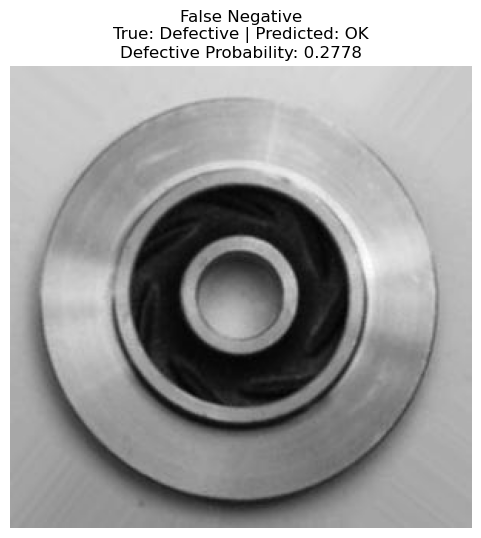

In [35]:
false_negative_path = false_negatives.iloc[0]["filepath"]

false_negative_image = Image.open(false_negative_path)

plt.figure(figsize=(6, 6))

plt.imshow(false_negative_image)

plt.title(
    "False Negative\n"
    "True: Defective | Predicted: OK\n"
    f"Defective Probability: {false_negatives.iloc[0]['probability_defective']:.4f}"
)

plt.axis("off")
plt.show()

In [36]:
# Select the first 3 false-positive examples

selected_false_positives = false_positives.head(3)

print("SELECTED FALSE POSITIVES")
print("=" * 60)

print(
    selected_false_positives[
        ["filepath", "probability_defective"]
    ].to_string(index=False)
)

SELECTED FALSE POSITIVES
                                                                                                filepath  probability_defective
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data\test\ok_front\cast_ok_0_1169.jpeg               0.365575
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data\test\ok_front\cast_ok_0_1172.jpeg               0.404199
C:\Users\RAGA AMIRTHA\Downloads\casting_data\casting_data\casting_data\test\ok_front\cast_ok_0_1174.jpeg               0.379224


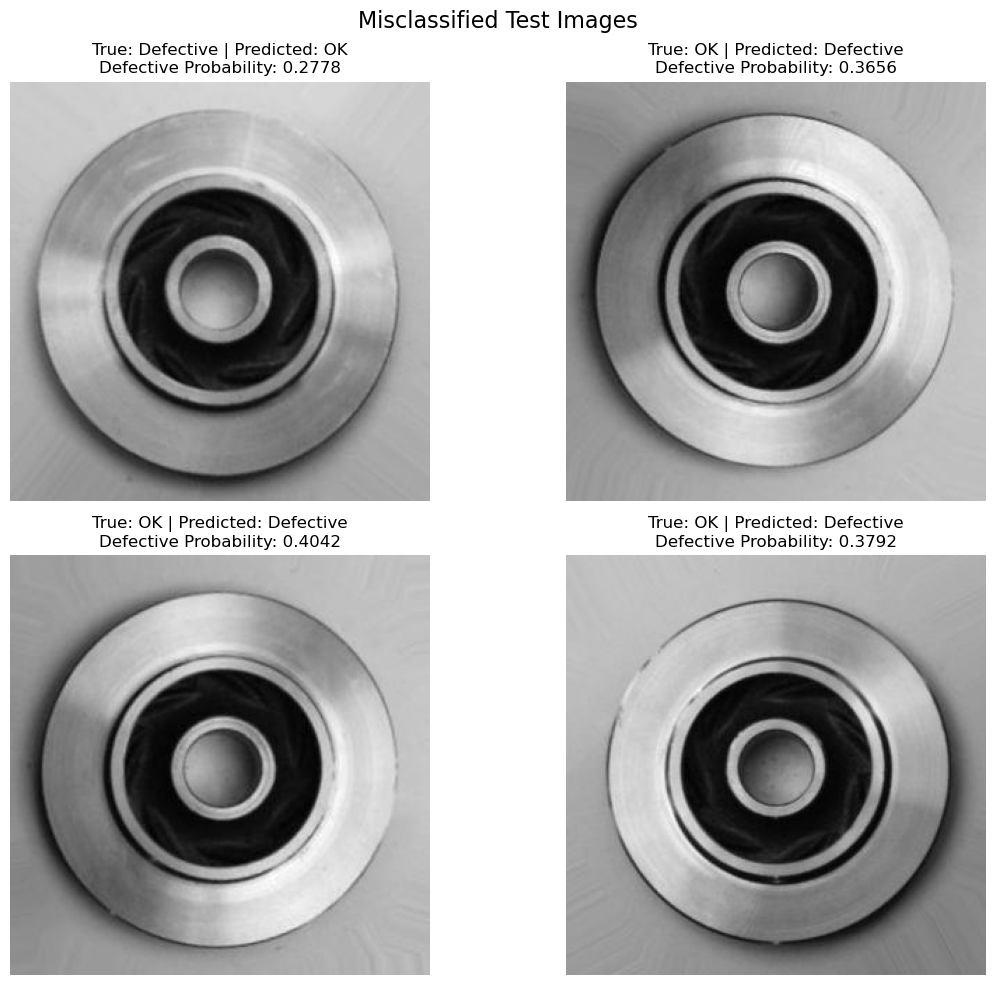

In [37]:
selected_errors = pd.concat([
    false_negatives,
    selected_false_positives
]).reset_index(drop=True)

plt.figure(figsize=(12, 10))

for i in range(len(selected_errors)):
    image_path = selected_errors.iloc[i]["filepath"]
    image = Image.open(image_path)

    true_label = (
        "Defective"
        if selected_errors.iloc[i]["true_label"] == 1
        else "OK"
    )

    predicted_label = (
        "Defective"
        if selected_errors.iloc[i]["predicted_label"] == 1
        else "OK"
    )

    probability = selected_errors.iloc[i]["probability_defective"]

    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap="gray")

    plt.title(
        f"True: {true_label} | Predicted: {predicted_label}\n"
        f"Defective Probability: {probability:.4f}"
    )

    plt.axis("off")

plt.suptitle(
    "Misclassified Test Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [38]:
# Compare default threshold with our selected threshold

threshold_comparison = []

for threshold in [0.50, BEST_THRESHOLD]:
    predictions = (test_probs >= threshold).astype(int)

    accuracy = accuracy_score(test_true, predictions)
    precision = precision_score(
        test_true,
        predictions,
        zero_division=0
    )
    recall = recall_score(
        test_true,
        predictions,
        zero_division=0
    )
    f1 = f1_score(
        test_true,
        predictions,
        zero_division=0
    )

    cm_temp = confusion_matrix(test_true, predictions)

    false_negatives_count = cm_temp[1, 0]
    false_positives_count = cm_temp[0, 1]

    threshold_comparison.append([
        threshold,
        accuracy,
        precision,
        recall,
        f1,
        false_negatives_count,
        false_positives_count
    ])

comparison_df = pd.DataFrame(
    threshold_comparison,
    columns=[
        "Threshold",
        "Accuracy",
        "Precision",
        "Defective Recall",
        "Defective F1",
        "False Negatives",
        "False Positives"
    ]
)

print("THRESHOLD COMPARISON")
print("=" * 80)
print(comparison_df.round(4).to_string(index=False))

THRESHOLD COMPARISON
 Threshold  Accuracy  Precision  Defective Recall  Defective F1  False Negatives  False Positives
       0.5    0.9832     0.9868            0.9868        0.9868                6                6
       0.3    0.9692     0.9556            0.9978        0.9762                1               21


In [39]:
model_save_path = "casting_defect_mobilenetv2.keras"

model.save(model_save_path)

print("Model saved successfully.")
print("File:", model_save_path)

Model saved successfully.
File: casting_defect_mobilenetv2.keras


In [40]:
import os

print("Model file exists:", os.path.exists(model_save_path))

if os.path.exists(model_save_path):
    print("Saved model:", os.path.abspath(model_save_path))
    print(
        "File size:",
        round(os.path.getsize(model_save_path) / (1024 * 1024), 2),
        "MB"
    )

Model file exists: True
Saved model: C:\Users\RAGA AMIRTHA\casting_defect_mobilenetv2.keras
File size: 9.2 MB
